In [7]:
import autoroot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from paper_plots.plot_config import set_plot_style

# --- Configuration ---
font_size = 40
figsize = (12, 8)
palette = 'tab20'

set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette='tab20')

T=1024
# --- Memory function ---
def exp(s, alpha):
    return np.exp(-s /(alpha*0.42857139))

def poly(s, alpha):
    return 1 / (1 + s) ** (1 / (alpha*0.3))

def impulse(s, alpha):
    alpha = np.floor(alpha* (T // 2))
    THRESHOLD = 0.5
    return ((s > alpha - THRESHOLD) & (s < alpha +THRESHOLD))

def airy(s, alpha):
    from scipy import special

    ai, aip, bi, bip = special.airy(40 * (s / T - 0.5 * alpha))

    return ai


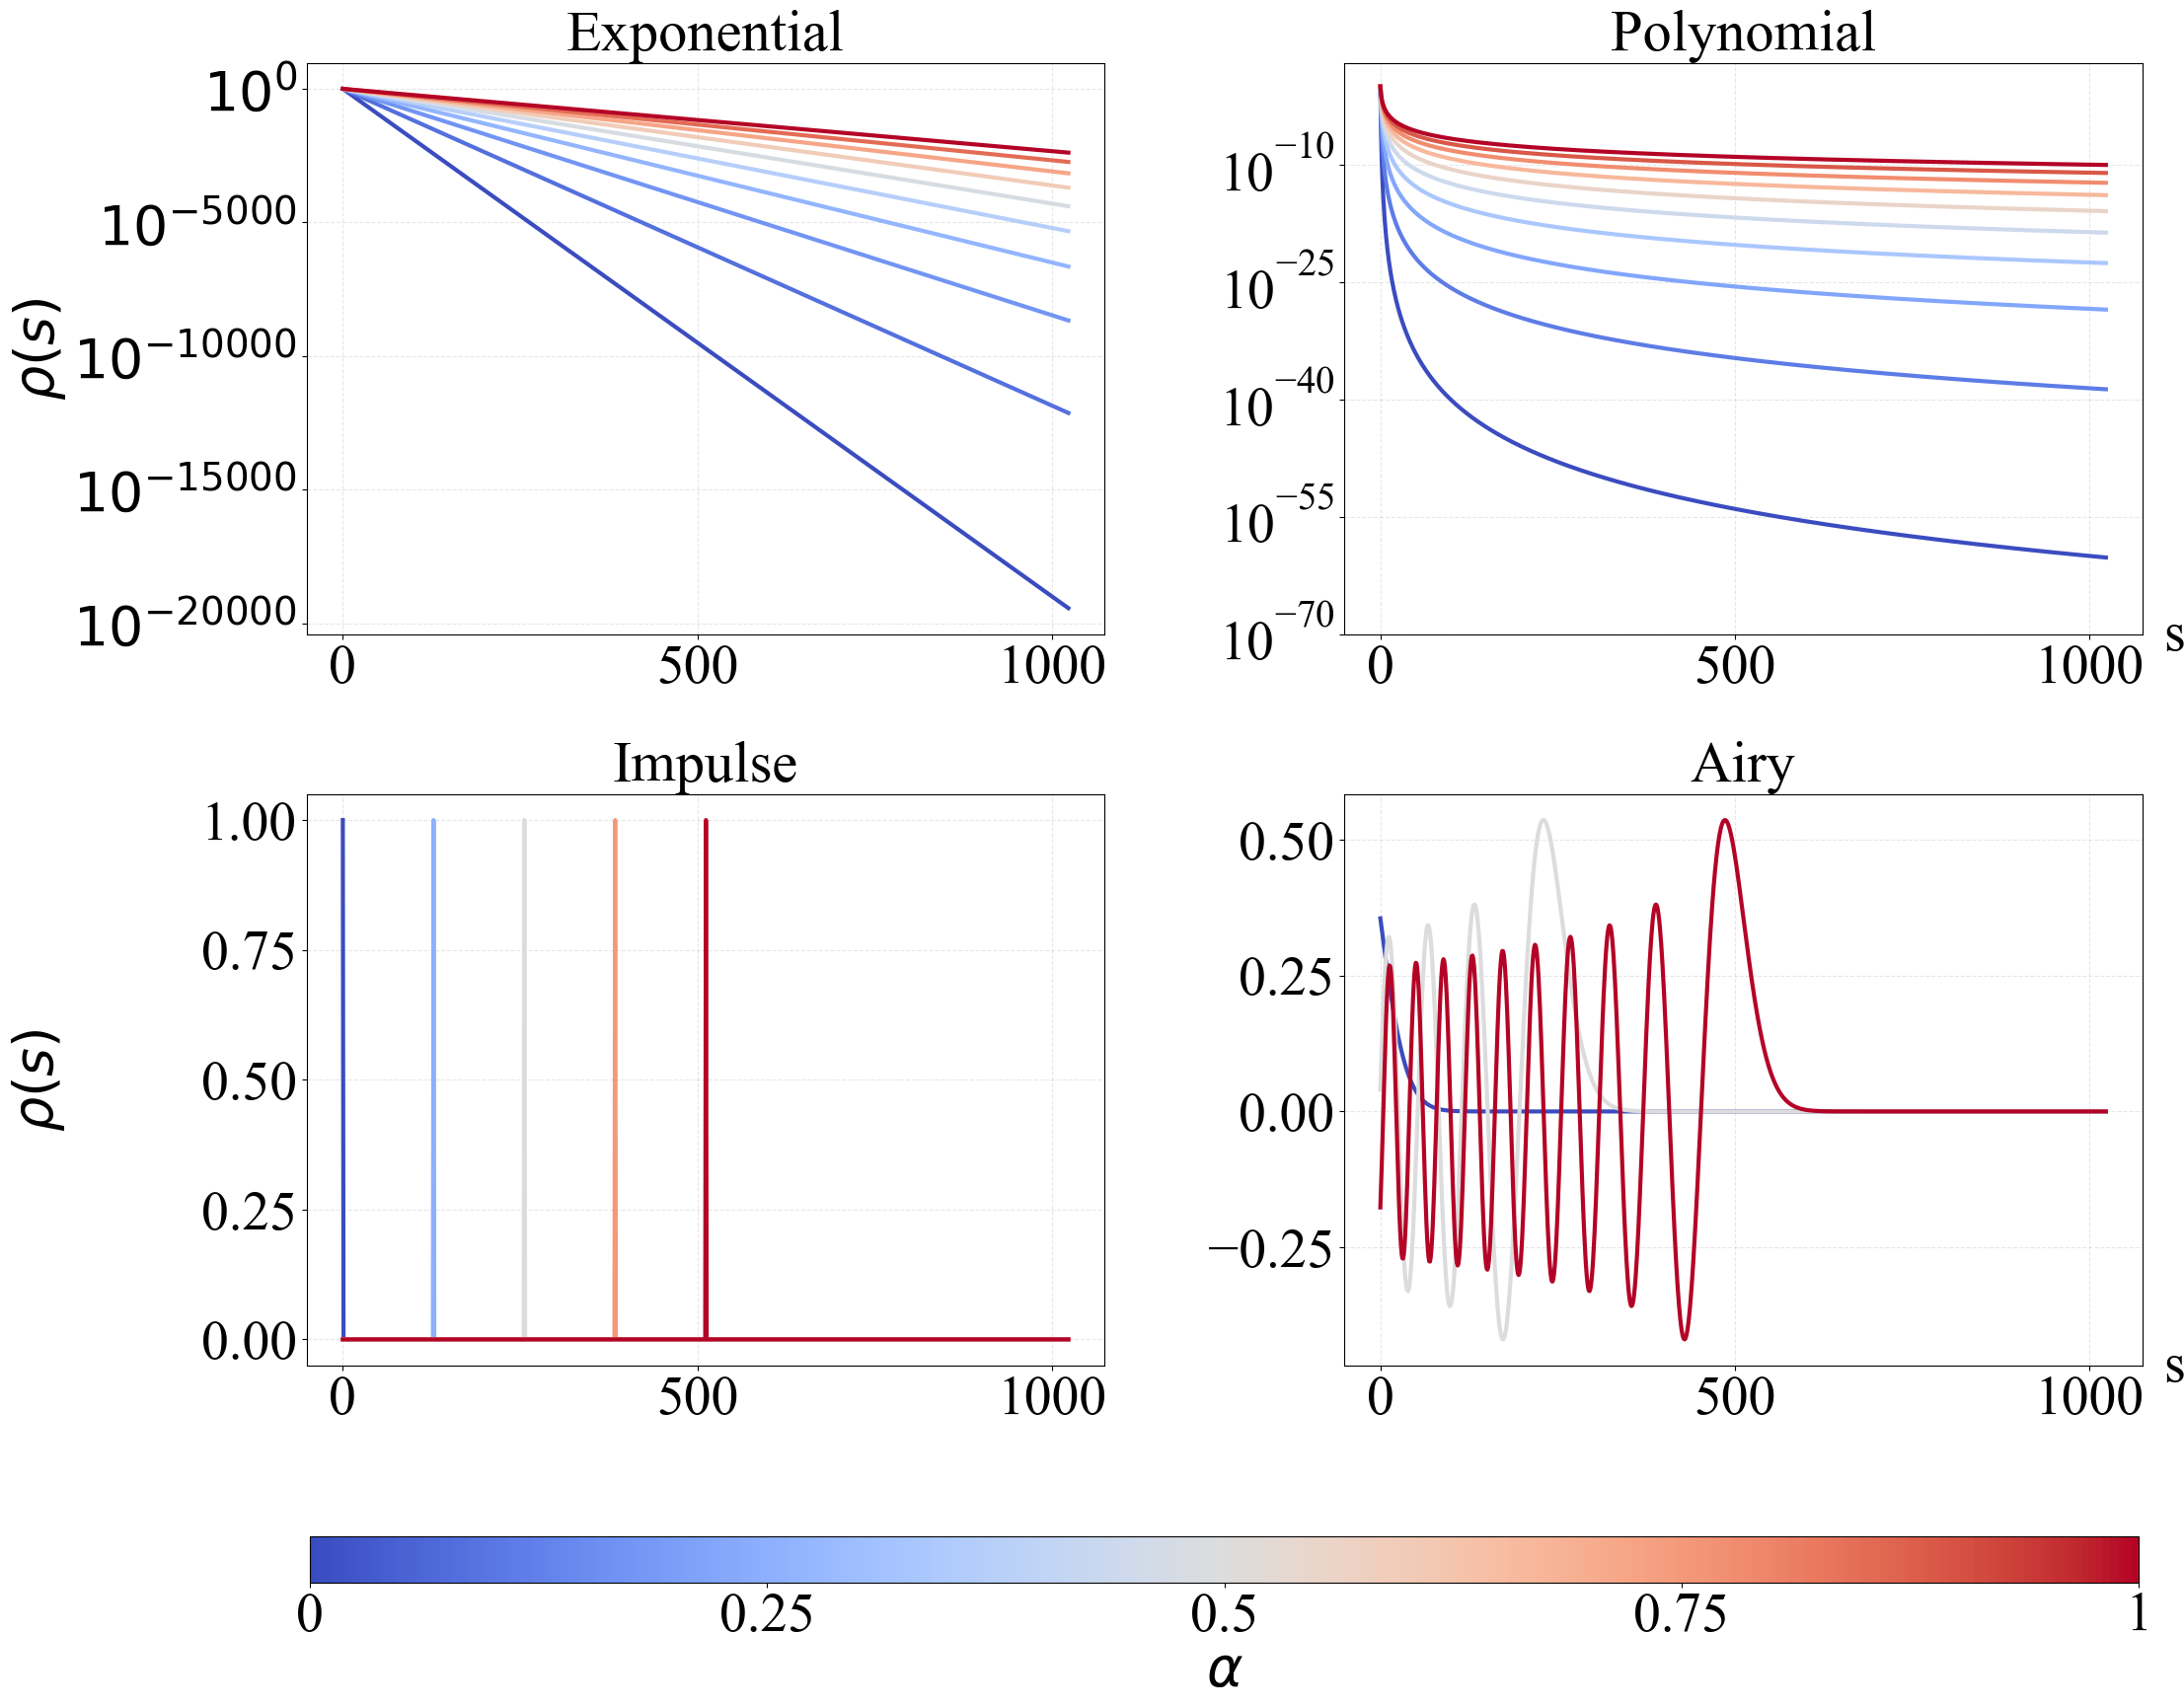

In [35]:
alpha_exp = np.array([0.05263158, 0.08433735, 0.11801242, 0.15384615, 0.19205298, 0.23287671, 0.27659574, 0.32352941, 0.3740458 , 0.42857139])/0.42857139
alpha_poly = np.array([0.05      , 0.07777778, 0.10555556, 0.13333333, 0.16111111, 0.18888889, 0.21666667, 0.24444444, 0.27222222, 0.3       ])/0.3
alpha_impluse = np.linspace(0,1,5)
alpha_airy = np.linspace(0,1,3)

# Create output directory
import os


# Generate s values
s = np.linspace(0, T-1, T)

# Use continuous colormap (blue to red)
cmap = plt.cm.coolwarm

# Create 2x2 subplot figure with GridSpec for more control
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(24, 20))
gs = GridSpec(3, 2, figure=fig, height_ratios=[1, 1, 0.1], hspace=0.4, wspace=0.3)

# Plot 1: Exponential Memory Function (top-left)
ax1 = fig.add_subplot(gs[0, 0])
norm = plt.Normalize(vmin=alpha_exp.min(), vmax=alpha_exp.max())

for i, alpha in enumerate(alpha_exp):
    # Calculate log directly: log(exp(-s/(alpha*c))) = -s/(alpha*c)
    log_y = -s / (alpha * 0.42857139)
    color = cmap(norm(alpha))
    ax1.plot(s, log_y, color=color, linewidth=3)

ax1.set_ylabel(r'$\rho(s)$')
ax1.set_title('Exponential')

# Set y-axis ticks to show exponential values
from matplotlib.ticker import FuncFormatter
def exp_formatter(x, pos):
    return f'$10^{{{int(x)}}}$'
ax1.yaxis.set_major_formatter(FuncFormatter(exp_formatter))

ax1.grid(True, alpha=0.3)

# Plot 2: Polynomial Memory Function (top-right)
ax2 = fig.add_subplot(gs[0, 1])
norm = plt.Normalize(vmin=alpha_poly.min(), vmax=alpha_poly.max())

for i, alpha in enumerate(alpha_poly):
    y = poly(s, alpha)
    color = cmap(norm(alpha))
    ax2.plot(s, y, color=color, linewidth=3)

ax2.set_xlabel('s')
ax2.set_title('Polynomial')
ax2.set_yscale('log')
ax2.set_ylim(bottom=1e-70)
# ax2.tick_params(labelleft=False)  # Hide y tick labels
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_label_coords(1.04, 0.04)  # Position x label at bottom right

# Plot 3: Impulse Memory Function (bottom-left)
ax3 = fig.add_subplot(gs[1, 0])
norm = plt.Normalize(vmin=alpha_impluse.min(), vmax=alpha_impluse.max())

for i, alpha in enumerate(alpha_impluse):
    y = impulse(s, alpha)
    color = cmap(norm(alpha))
    ax3.plot(s, y, color=color, linewidth=3)

ax3.set_ylabel(r'$\rho(s)$')
ax3.yaxis.set_label_coords(-0.3, 0.5)
ax3.set_title('Impulse')
ax3.grid(True, alpha=0.3)

# Plot 4: Airy Memory Function (bottom-right)
ax4 = fig.add_subplot(gs[1, 1])
norm = plt.Normalize(vmin=alpha_airy.min(), vmax=alpha_airy.max())

for i, alpha in enumerate(alpha_airy):
    y = airy(s, alpha)
    color = cmap(norm(alpha))
    ax4.plot(s, y, color=color, linewidth=3)

ax4.set_xlabel('s')
ax4.set_title('Airy')
# ax4.tick_params(labelleft=False)  # Hide y tick labels
ax4.grid(True, alpha=0.3)
ax4.xaxis.set_label_coords(1.04, 0.04)  # Position x label at bottom right

# Add colorbar at the bottom spanning both columns
ax_cbar = fig.add_subplot(gs[2, :])
ax_cbar.axis('off')

# Create scalar mappable for colorbar
norm = plt.Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create horizontal colorbar
cbar = plt.colorbar(sm, ax=ax_cbar, orientation='horizontal', 
                    fraction=0.8, aspect=40, pad=0.05)
cbar.set_label(r'$\alpha$', fontsize=font_size)

# Set tick labels to show the normalized alpha range (0 to 1)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
cbar.set_ticklabels(['0', '0.25', '0.5', '0.75', '1'])

# Save the combined figure
plt.savefig(f'memory_function_combined.pdf', dpi=300, bbox_inches='tight')
plt.show()


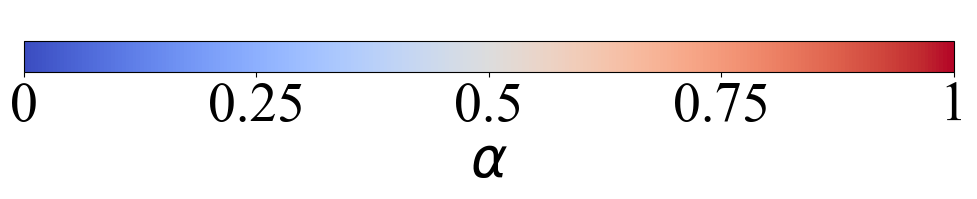

In [9]:
# Create a plot with just the colorbar
cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=0, vmax=1)

# Create figure for colorbar only
fig, ax_cbar = plt.subplots(figsize=(figsize[0], 2))
ax_cbar.axis('off')

# Create scalar mappable for colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create horizontal colorbar
cbar = plt.colorbar(sm, ax=ax_cbar, orientation='horizontal', 
                    fraction=0.8, aspect=30)
cbar.set_label(r'$\alpha$', fontsize=font_size)

# Set tick labels to show the normalized alpha range (0 to 1)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
cbar.set_ticklabels(['0', '0.25', '0.5', '0.75', '1'])

plt.savefig('memory_function_colorbar.pdf', bbox_inches='tight')
plt.show()

In [ ]:

# # Also save individual plots for reference
# # Plot 1: Exponential Memory Function
# fig, ax = plt.subplots(figsize=figsize)
# norm = plt.Normalize(vmin=alpha_exp.min(), vmax=alpha_exp.max())

# for i, alpha in enumerate(alpha_exp):
#     # Calculate log directly: log(exp(-s/(alpha*c))) = -s/(alpha*c)
#     log_y = -s / (alpha * 0.42857139)
#     color = cmap(norm(alpha))
#     ax.plot(s, log_y, color=color, linewidth=3)

# ax.set_xlabel('s')
# ax.set_ylabel(r'$\rho(s)$')

# # Set y-axis ticks to show exponential values
# ax.yaxis.set_major_formatter(FuncFormatter(exp_formatter))

# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.savefig(f'memory_function_exp.pdf', dpi=300, bbox_inches='tight')
# plt.show()

# # Plot 2: Polynomial Memory Function
# fig, ax = plt.subplots(figsize=figsize)
# norm = plt.Normalize(vmin=alpha_poly.min(), vmax=alpha_poly.max())

# for i, alpha in enumerate(alpha_poly):
#     y = poly(s, alpha)
#     color = cmap(norm(alpha))
#     ax.plot(s, y, color=color, linewidth=3)

# ax.set_xlabel('s')
# ax.set_ylabel(r'$\rho(s)$')
# ax.set_yscale('log')
# ax.set_ylim(bottom=1e-50)
# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.savefig(f'memory_function_poly.pdf', dpi=300, bbox_inches='tight')
# plt.show()

# # Plot 3: Impulse Memory Function
# fig, ax = plt.subplots(figsize=figsize)
# norm = plt.Normalize(vmin=alpha_impluse.min(), vmax=alpha_impluse.max())

# for i, alpha in enumerate(alpha_impluse):
#     y = impulse(s, alpha)
#     color = cmap(norm(alpha))
#     ax.plot(s, y, color=color, linewidth=3)

# ax.set_xlabel('s')
# ax.set_ylabel(r'$\rho(s)$')
# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.savefig(f'memory_function_impulse.pdf', dpi=300, bbox_inches='tight')
# plt.show()

# # Plot 4: Airy Memory Function
# fig, ax = plt.subplots(figsize=figsize)
# norm = plt.Normalize(vmin=alpha_airy.min(), vmax=alpha_airy.max())

# for i, alpha in enumerate(alpha_airy):
#     y = airy(s, alpha)
#     color = cmap(norm(alpha))
#     ax.plot(s, y, color=color, linewidth=3)

# ax.set_xlabel('s')
# ax.set_ylabel(r'$\rho(s)$')
# ax.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.savefig(f'memory_function_airy.pdf', dpi=300, bbox_inches='tight')
# plt.show()